# Train and Validate
* Train a model across the specified training sites and sampling approach
* Validate the model at the excluded site

## Todo
* Pull out probabilities using model.predict_proba(observations_to_predict)

In [4]:
import pathlib
import numpy
import dask.distributed
import pandas
import joblib

module_path = pathlib.Path.cwd().parent.parent / 'scripts'
import sys
if str(module_path) not in sys.path:
    sys.path.append(str(module_path))
import utils
import sentinel2
import training
import sampling
import plotting

%load_ext autoreload
%autoreload 2

In [5]:
cluster = dask.distributed.LocalCluster(
    threads_per_worker=1,   n_workers=4,                                 
    config={
        "distributed.worker.memory.target": 0.80, 
        "distributed.worker.memory.spill": 0.85,
        "distributed.worker.memory.pause": 0.90
    }
)
client = dask.distributed.Client(cluster)
display(client)

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:63644/status,
Dashboard: http://127.0.0.1:63644/status,Workers: 4
Total threads: 4,Total memory: 31.73 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:52467,Workers: 0
Dashboard: http://127.0.0.1:63644/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:52495,Total threads: 1
Dashboard: http://127.0.0.1:52496/status,Memory: 7.93 GiB
Nanny: tcp://127.0.0.1:52470,


In [6]:
uav_classes_to_ignore = ['Shadow', 'Glare']

In [7]:
# Mappings of Satellite classes to consider from UAV classes - 100% purity
satellite_classes_5 = {'Seagrass': 1, 'Missing': 2, 'Unvegetated': 3, 'Water': 4, 'Seagrass submerged': 5, "Vegetated": 6}
satellite_classes_from_uav_classes_5 = {
    'Seagrass': ['Seagrass'],
    'Seagrass submerged': ['Seagrass submerged'],
    'Unvegetated': ['Unvegetated'],                            
    'Water': ['Water'],
    'Vegetated': ['Microphytobenthos'],
    'Missing': ['Gracilaria', 'Ulva', 'Cystophora', 'Hormosira', 'Gracilaria submerged', 'Submerged vegetation',
              'Brown algae mixed', 'Green algae mixed', 'Filamentous brown algae',
              'Ulva mats', 'Terrestrial', 'Red algae mixed', 'Saltmarsh', 'Rock'],
}

In [8]:
# Mappings of Satellite classes to consider from UAV classes - 100% purity
satellite_classes_4 = {'Seagrass': 1, 'Mixed': 2, 'Unvegetated': 3, 'Water': 4}
satellite_classes_from_uav_classes_4 = {
    'Seagrass': ['Seagrass', 'Seagrass submerged'],
    'Unvegetated': ['Saltmarsh', 'Unvegetated', 'Rock'],                            
    'Water': ['Water'],
    'Mixed': ['Gracilaria', 'Ulva', 'Cystophora', 'Hormosira', 'Gracilaria submerged', 'Submerged vegetation',
              'Brown algae mixed', 'Microphytobenthos', 'Green algae mixed', 'Filamentous brown algae',
              'Ulva mats', 'Terrestrial', 'Red algae mixed'],
}

In [9]:
# Mappings of Satellite classes to consider from UAV classes - 98% purity
satellite_classes_all = {'Seagrass': 1, 'Seagrass submerged': 2, 'Gracilaria': 3, 'Gracilaria submerged': 4, 
                           'Ulva': 5, 'Submerged vegetation': 9, 'Microphytobenthos': 10, 'Satmarsh': 14,
                           'Unvegetated': 15, 'Water': 16, 'Terrestrial': 18, 'Rock': 19, 'Mixed': 22,}
satellite_classes_from_uav_classes_all = {
    'Seagrass': ['Seagrass'],
    'Gracilaria': ['Gracilaria'],
    'Ulva': ['Ulva', 'Ulva mats'],
    'Satmarsh': ['Saltmarsh', ],
    'Terrestrial': ['Terrestrial'],
    'Unvegetated': ['Unvegetated'],                            
    'Water': ['Water'],
    'Mixed': ['Cystophora', 'Hormosira','Brown algae mixed', 'Green algae mixed', 
          'Filamentous brown algae', 'Red algae mixed'],
    'Submerged vegetation': ['Submerged vegetation'],
    'Gracilaria submerged': ['Gracilaria submerged'],
    'Seagrass submerged': ['Seagrass submerged'],
    'Rock': ['Rock'],
    'Microphytobenthos': ['Microphytobenthos'], 
}

In [10]:
# Mappings of Satellite classes to consider from UAV classes - 98% purity
satellite_classes_grouped = {'Seagrass': 1, 'Seagrass submerged': 2, 'Gracilaria': 3,  
                           'Ulva': 5, 'Submerged vegetation': 9, 'Microphytobenthos': 10, 'Satmarsh': 14,
                           'Unvegetated': 15, 'Water': 16, 'Terrestrial': 18, 'Rock': 19, 'Mixed': 22,}
satellite_classes_from_uav_classes_grouped = {
    'Seagrass': ['Seagrass'],
    'Gracilaria': ['Gracilaria', 'Gracilaria submerged'],
    'Ulva': ['Ulva', 'Ulva mats'],
    'Satmarsh': ['Saltmarsh', ],
    'Terrestrial': ['Terrestrial'],
    'Unvegetated': ['Unvegetated'],                            
    'Water': ['Water'],
    'Mixed': ['Cystophora', 'Hormosira','Brown algae mixed', 'Green algae mixed', 
          'Filamentous brown algae', 'Red algae mixed'],
    'Submerged vegetation': ['Submerged vegetation'],
    'Seagrass submerged': ['Seagrass submerged'],
    'Rock': ['Rock'],
    'Microphytobenthos': ['Microphytobenthos'], 
}

In [11]:
# Mappings of Satellite classes to consider from UAV classes - 98% purity
satellite_classes_9 = {'Seagrass': 1, 'Seagrass submerged': 2, 'Gracilaria': 3,  
                           'Ulva': 5, 'Submerged vegetation': 9, 'Microphytobenthos': 10,
                           'Water': 16, 'Small': 22, 'Other': 23,}
satellite_classes_from_uav_classes_9 = {
    'Seagrass': ['Seagrass'],
    'Gracilaria': ['Gracilaria', 'Gracilaria submerged'],
    'Ulva': ['Ulva', 'Ulva mats'],
    'Other': ['Unvegetated', 'Terrestrial', 'Saltmarsh', 'Rock'],                            
    'Water': ['Water'],
    'Small': ['Cystophora', 'Hormosira','Brown algae mixed', 'Green algae mixed', 
          'Filamentous brown algae', 'Red algae mixed'],
    'Submerged vegetation': ['Submerged vegetation'],
    'Seagrass submerged': ['Seagrass submerged'],
    'Microphytobenthos': ['Microphytobenthos'], 
}

In [12]:
all_training_sites =  ["CatlinsLake", "CatlinsRiverMouth", "Childrens", "Duvauchelle", "Robinsons", "Takamatua",
                       "Purau", "Ihutai", "IveyBay_Nov25", "IveyBay_Feb26", "LeftBank_Nov25", "LeftBank_Feb26",
                       "Paremata_Nov25", "Paremata_Feb26", "Paremata_Feb25", "ThePoint_Nov25", "ThePoint_Feb26",
                       "Takapuwahia_Nov25", "Takapuwahia_Feb26", "IveyBay_ThePoint_LeftBank_Oct24"]

training_sites_akaroa = ["Duvauchelle", "Robinsons", "Childrens", "Takamatua"] 
training_sites_banks = ["Duvauchelle", "Robinsons", "Childrens", "Takamatua", "Purau", "Ihutai"] 
training_sites_ihutai = ["Ihutai"] 
training_sites_SI = ["CatlinsLake", "CatlinsRiverMouth", "Childrens", "Duvauchelle", "Robinsons", "Takamatua",
                     "Purau", "Ihutai"] 

# Values to edit
* Make sure you change the `model_file` name when experimenting

In [17]:
sample_method = "sampling_2"
method_2_threshold = .8 # 1.0 .99 .98 .97 .95 .90
test_threshold = 0.1
max_cloud_cover = 10 # percentage

In [18]:
training_sites = all_training_sites # all_training_sites training_sites_banks training_sites_ihutai
model_description = f"RF_model_filtered_dates_13_class_{int(test_threshold*100)}_percent_test" 

satellite_classes = satellite_classes_all
satellite_classes_from_uav_classes = satellite_classes_from_uav_classes_all

In [19]:
model_path = utils.get_models_path(
    sample_method=sample_method,
    method_2_threshold=method_2_threshold,
    use_threshold=True,
    max_cloud_cover=max_cloud_cover)
model_path  = model_path / model_description
model_path.mkdir(parents=True, exist_ok=True)
model_file = model_path / "model.joblib"

# Cells to run
* Train and save model
* Review model
  * satellite bands of each UAV class
  * satellite bands of each satellite class
  * importance of satellite bands in trained model
* Validation
  * Predict excluded site
  * Plot confusion matrix comparing prediction to UAV classifications

In [20]:
data_path = utils.get_data_path()
utils.create_data_folders()
uav_labels_file = data_path / "ELF24505_ClassificationClasses.txt"
sample_folder = utils.get_samples_path(
    sample_method=sample_method,
    method_2_threshold=method_2_threshold,
    use_threshold=True,
    max_cloud_cover=max_cloud_cover,
    filtered=True,
)

validation_path = utils.get_validation_path(
    sample_method=sample_method,
    method_2_threshold=method_2_threshold,
    use_threshold=True,
    max_cloud_cover=max_cloud_cover,
    filtered=True,
)
validation_path = validation_path / model_description
validation_path.mkdir(parents=True, exist_ok=True)
test_prediction_file = validation_path / "predictions.csv"

In [21]:
sample_folder

WindowsPath('C:/Local/repos/seagrass-detection/data/training/tide_thresholded_cloud_10_filtered/sampling_2_80_percent')

### Train and save model

In [22]:
if not model_file.exists():

    # Split into test and train - todo
    training_dataframe, test_dataframe = training.randomise_to_test_and_training_across_sites(
        training_sites=training_sites,
        samples_path=sample_folder,
        uav_labels_file=uav_labels_file,
        uav_classes_to_ignore=uav_classes_to_ignore,
        satellite_classes=satellite_classes,
        satellite_from_uav_classes=satellite_classes_from_uav_classes,
        test_threshold=test_threshold)
    model, model_columns = training.train_random_forest_classifier(
        training_dataframe=training_dataframe,)
    
    # Save model and feature names
    joblib.dump(model, model_file); # , compress=3);
    model_columns.to_csv(model_file.with_name("feature_names.csv"), index=False)

    # Save split test and train dataset
    joblib.dump(model, model_file); # , compress=3);
    training_dataframe.to_csv(model_file.with_name("train.csv"), index=False)
    test_dataframe.to_csv(model_file.with_name("test.csv"), index=False)
    
    # Save a record of the classes considered in training
    satellite_classes_dataframe = pandas.DataFrame.from_dict(satellite_classes, orient='index', columns=['satellite_class_id'])
    satellite_classes_dataframe['uav_class_ids'] = satellite_classes_dataframe.index.map(lambda key: f"{satellite_classes_from_uav_classes[key]}")
    satellite_classes_dataframe.to_csv(model_file.with_name("class_mappings.csv"), index=True)

    # Save a summary of the training data
    training_data_summary=pandas.DataFrame(training_dataframe['satellite_class_id'].value_counts())
    training_data_summary["satellite_class_name"] = training_data_summary.index.map(lambda index: next((key for key, value in satellite_classes.items() if value == int(index)), None) )
    training_data_summary = training_data_summary[["satellite_class_name", "count"]] # Change column order
    training_data_summary.to_csv(model_file.with_name("training_data_summary.csv"))
    
else:
    print(f"Model '{model_file.parent.name}' already exists. Delete if you want to recreate it.")
    training_data_summary = pandas.read_csv(model_file.with_name("training_data_summary.csv"))
    training_dataframe = pandas.read_csv(model_file.with_name("train.csv"))
    test_dataframe = pandas.read_csv(model_file.with_name("test.csv"))

training_data_summary

print("Write out test vs train values")

	Load in sites: ['CatlinsLake', 'CatlinsRiverMouth', 'Childrens', 'Duvauchelle', 'Robinsons', 'Takamatua', 'Purau', 'Ihutai', 'IveyBay_Nov25', 'IveyBay_Feb26', 'LeftBank_Nov25', 'LeftBank_Feb26', 'Paremata_Nov25', 'Paremata_Feb26', 'Paremata_Feb25', 'ThePoint_Nov25', 'ThePoint_Feb26', 'Takapuwahia_Nov25', 'Takapuwahia_Feb26', 'IveyBay_ThePoint_LeftBank_Oct24']
	WARNING - no training data for site Purau. Skipping this site.Rerun `extract_training_data` for this site if data is expected.
	WARNING - no training data for site IveyBay_Feb26. Skipping this site.Rerun `extract_training_data` for this site if data is expected.
	Map UAV training ids to the specified satellite training ids
	Train a Random Forest Model
Write out test vs train values


In [23]:
training_data_summary

,satellite_class_name,count
satellite_class_id,,
15,Unvegetated,82271
16,Water,30782
1,Seagrass,7461
3,Gracilaria,3505
9,Submerged vegetation,3154
5,Ulva,2331
18,Terrestrial,1822
14,Satmarsh,1416
4,Gracilaria submerged,1240


### Review model

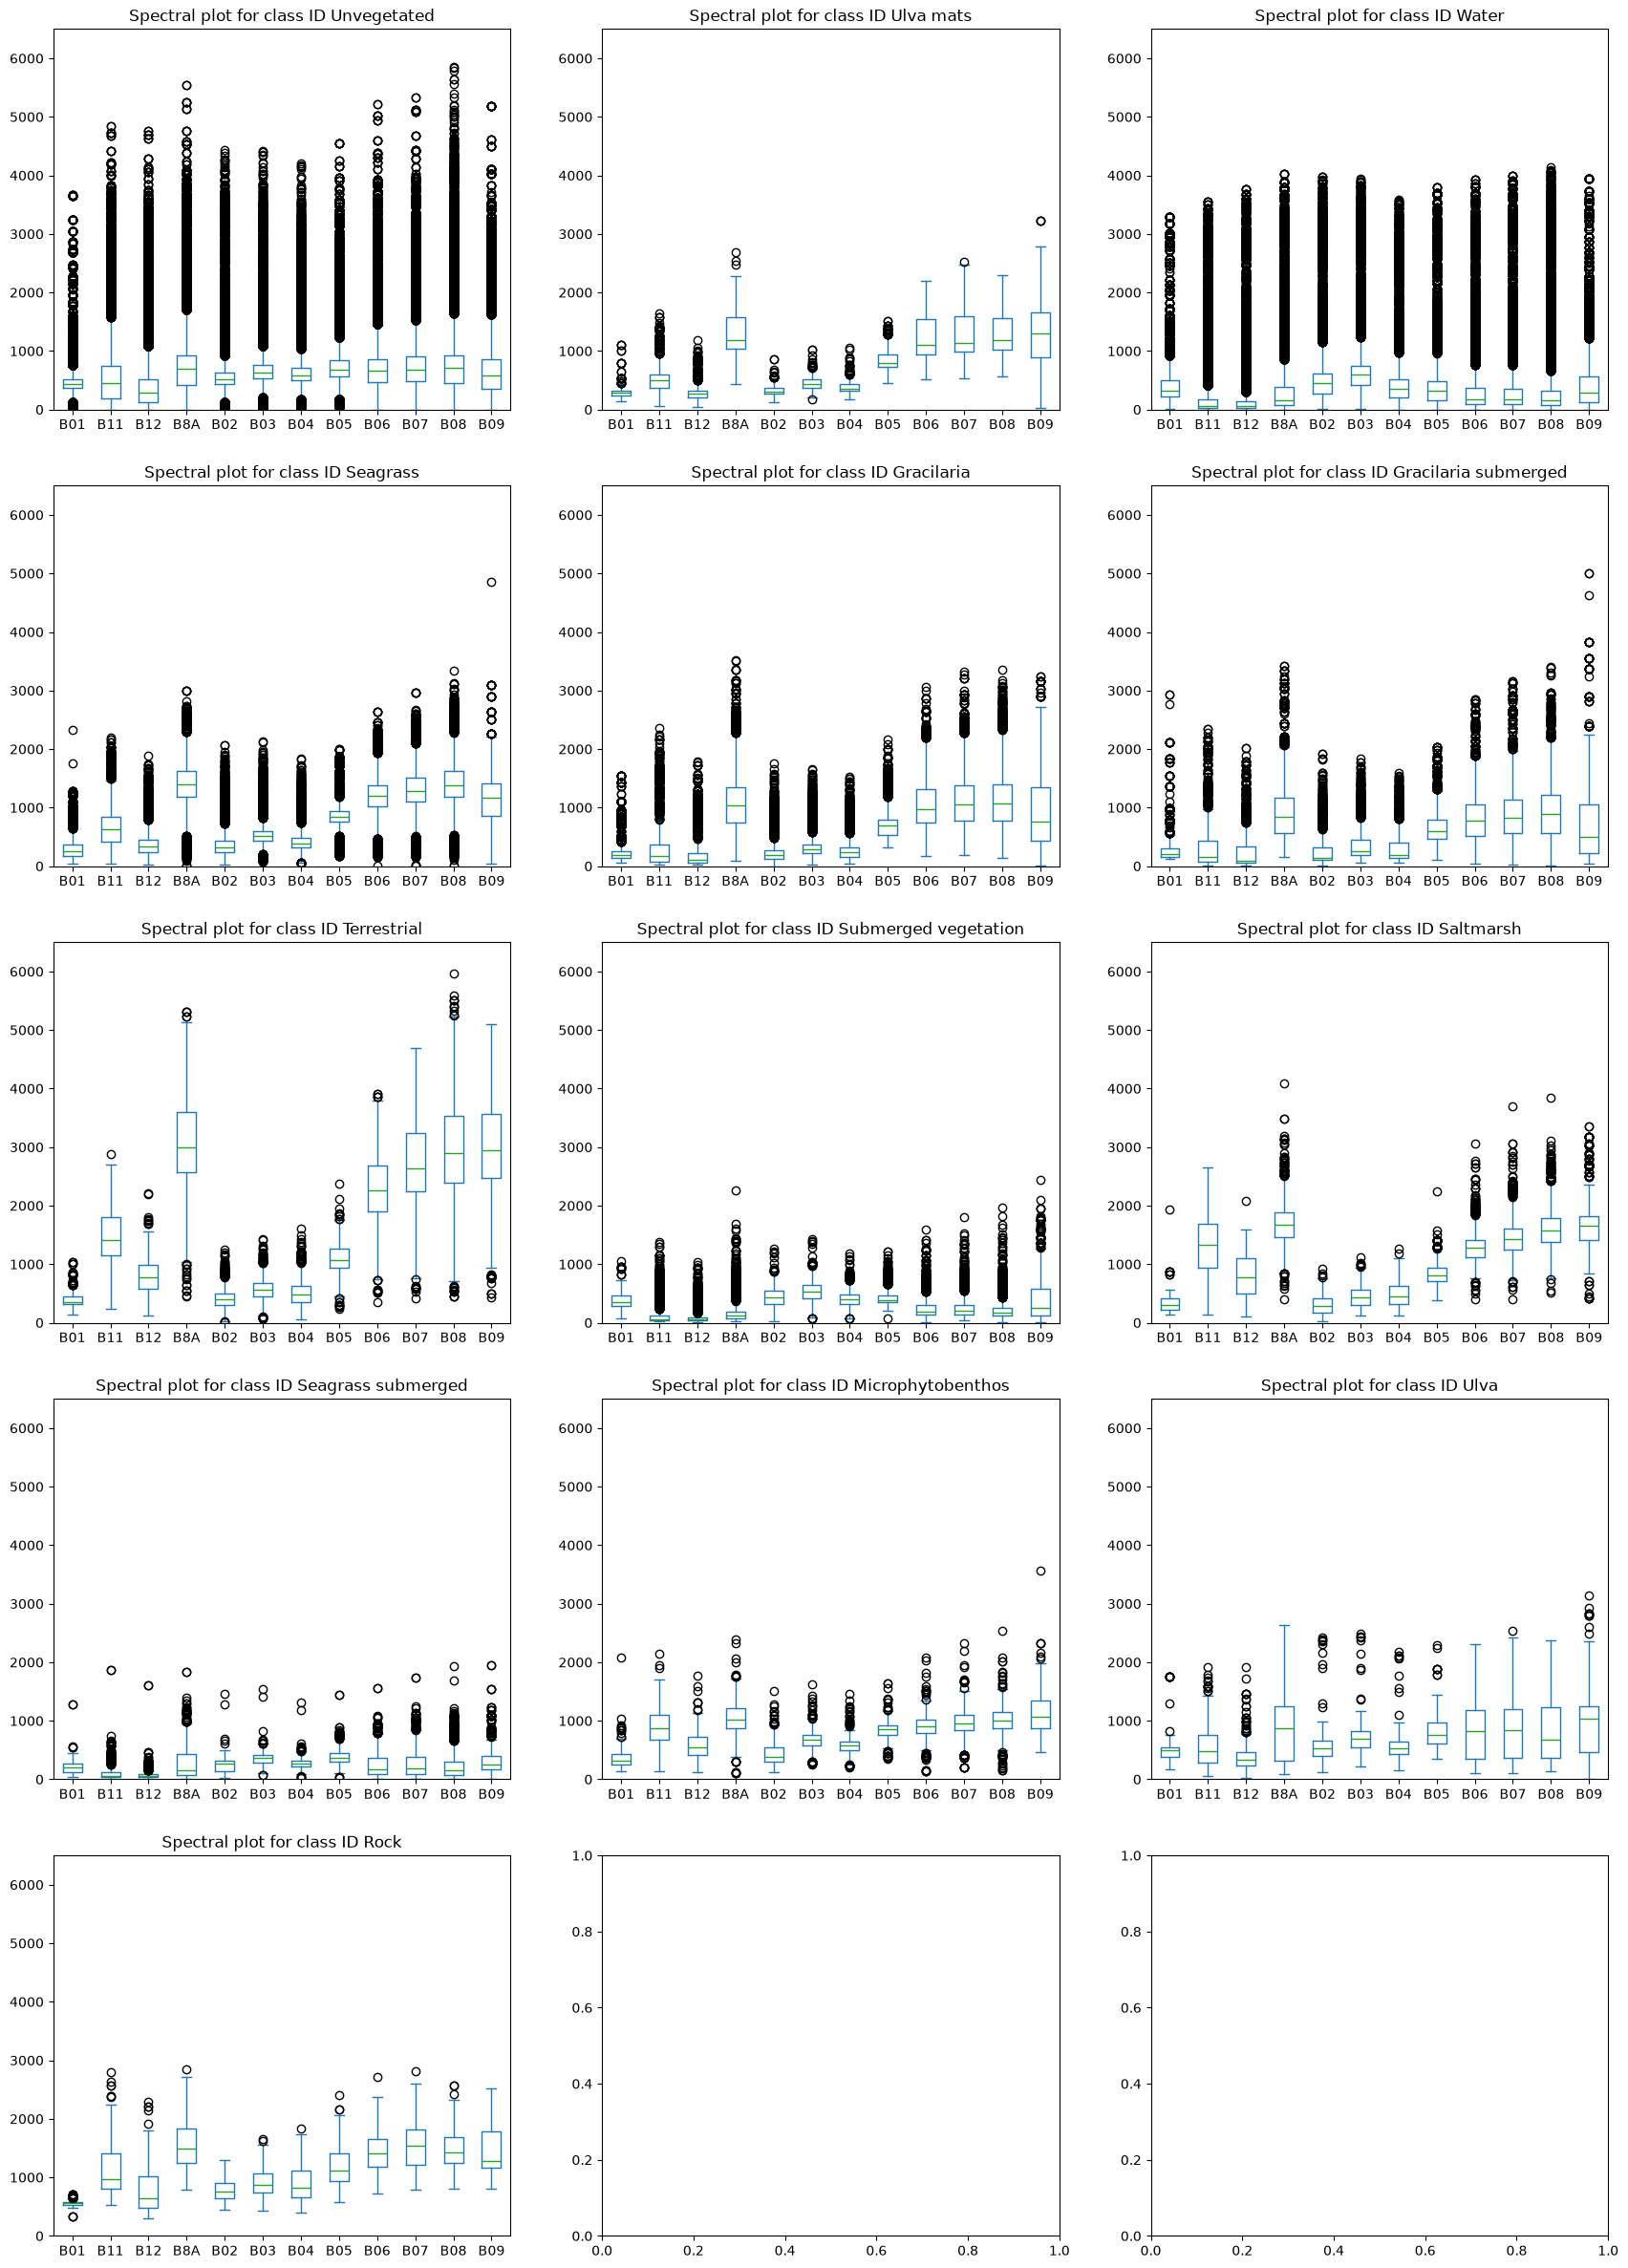

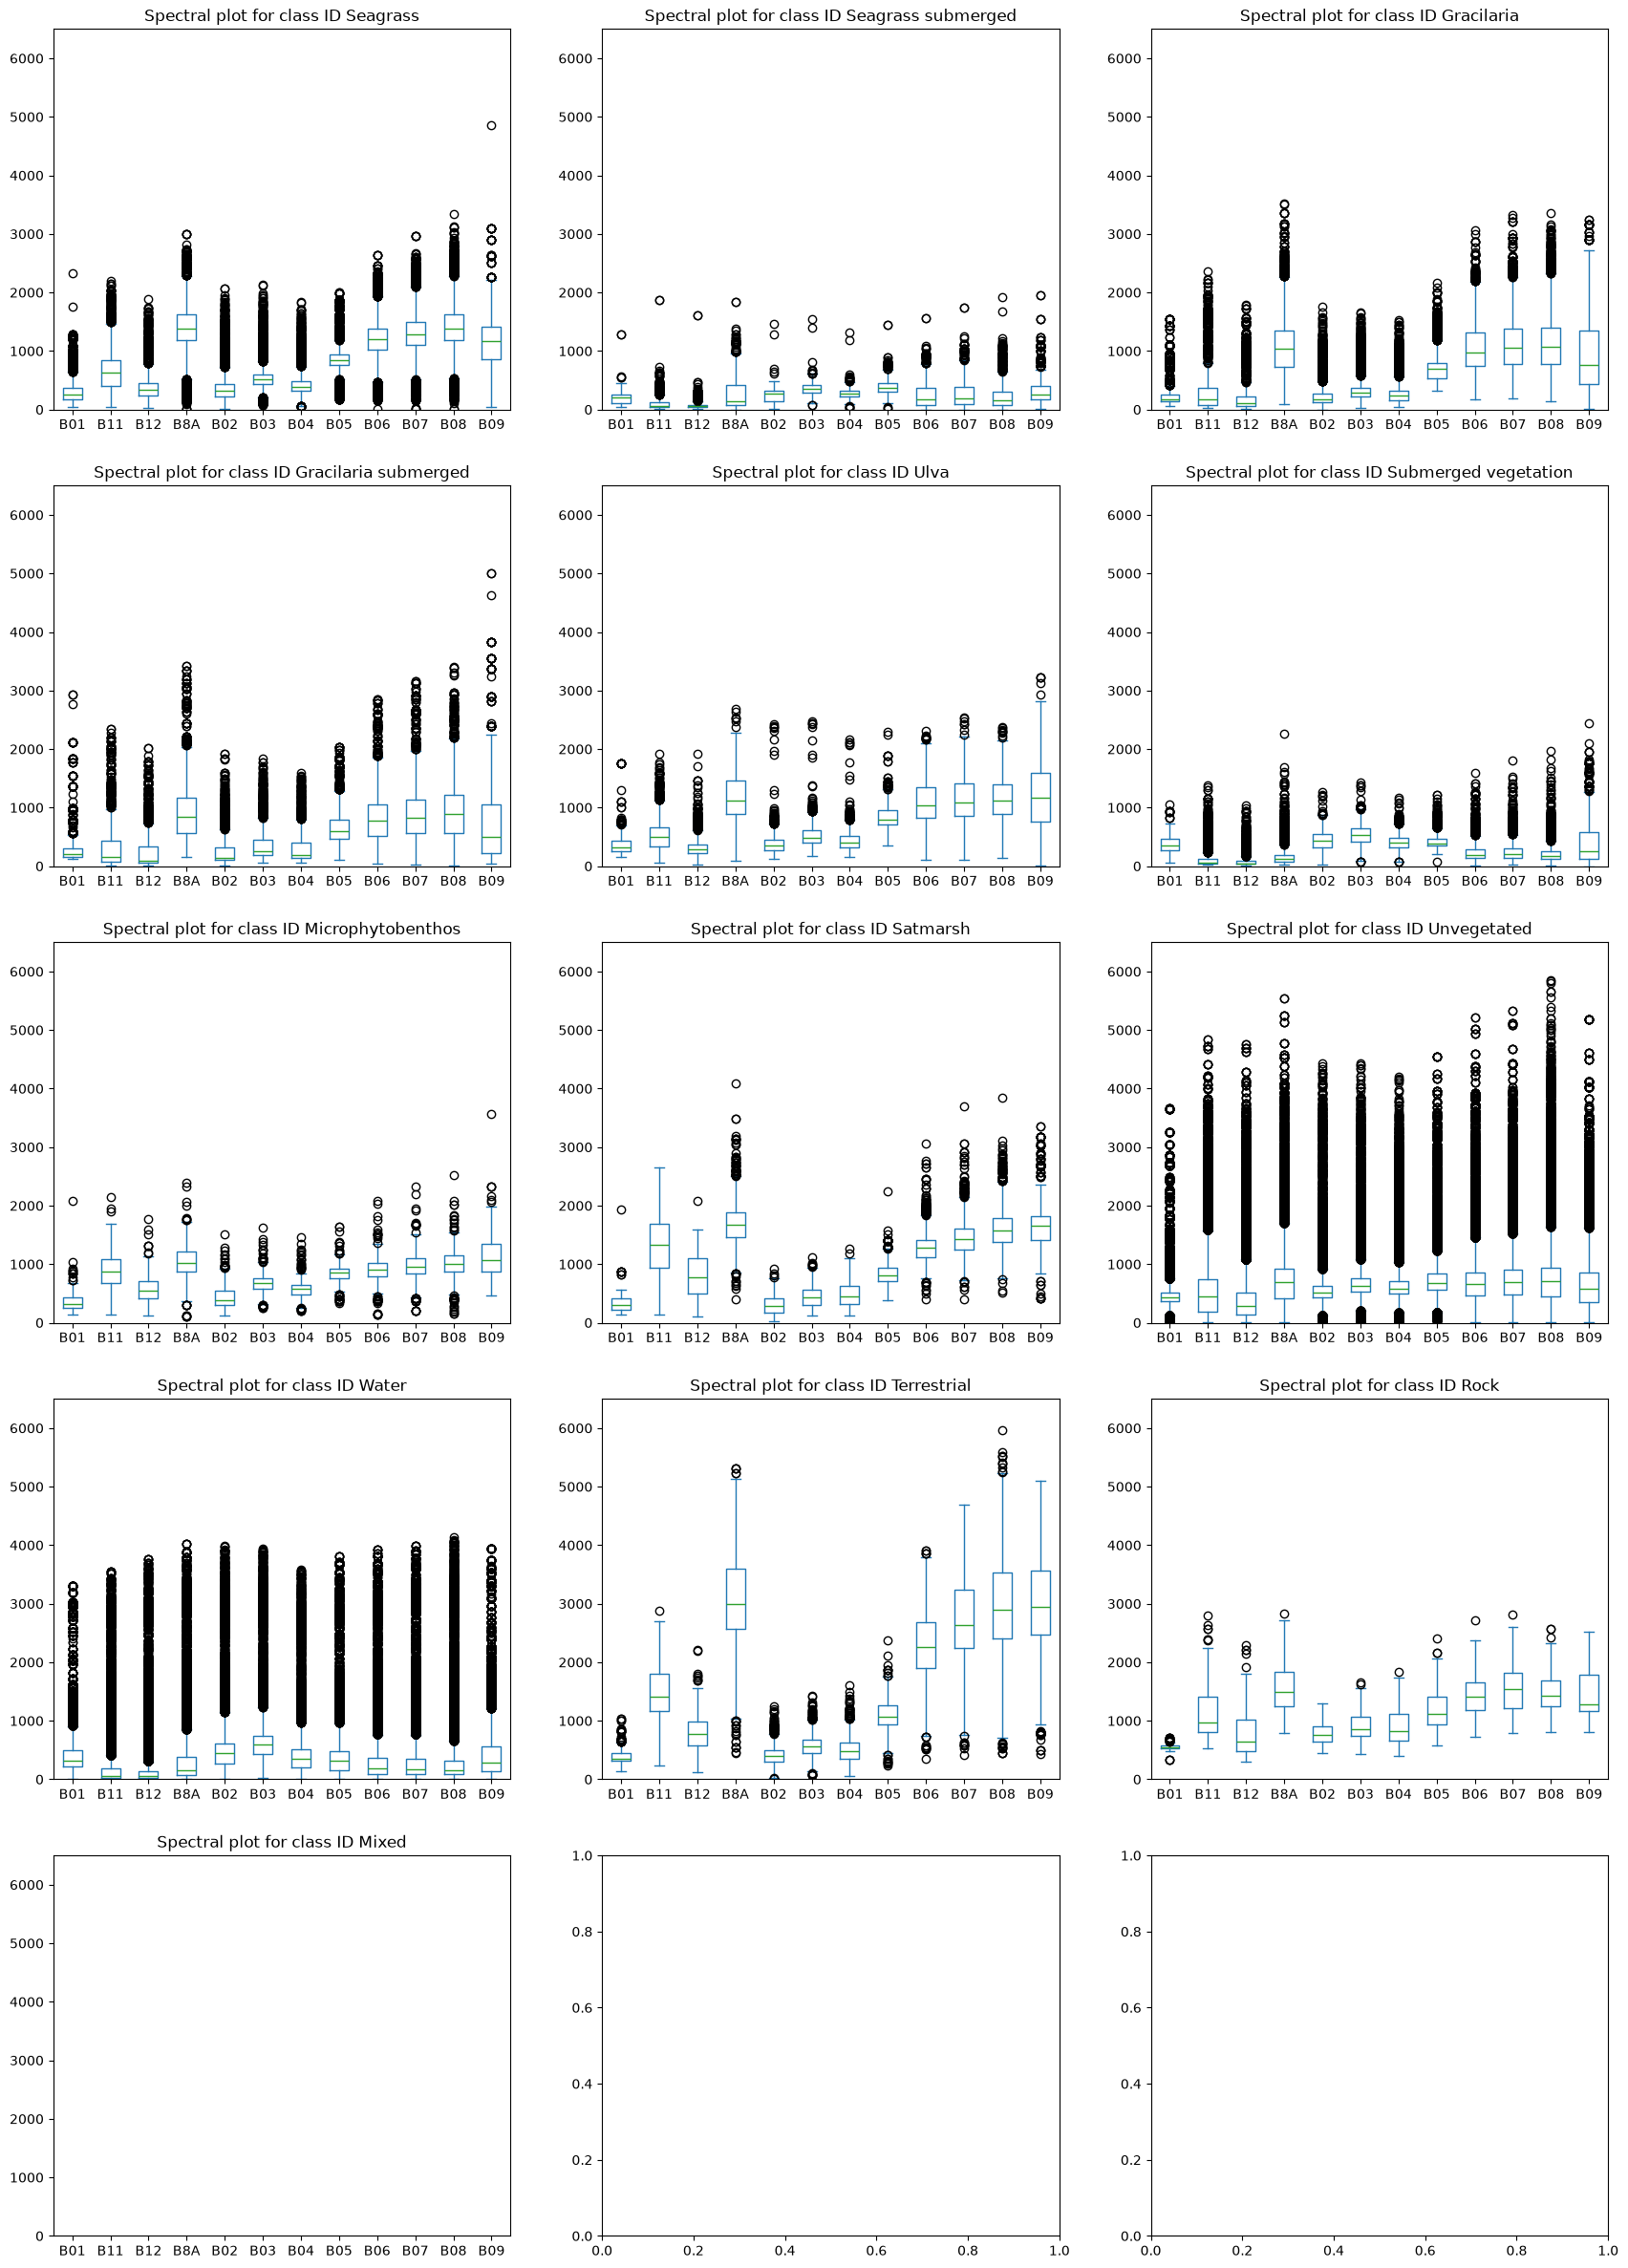

In [24]:
plotting.plot_training_data_class_distribution(training_dataframe=training_dataframe, model_file=model_file,
                                               uav_labels_file=uav_labels_file, satellite_labels=satellite_classes)

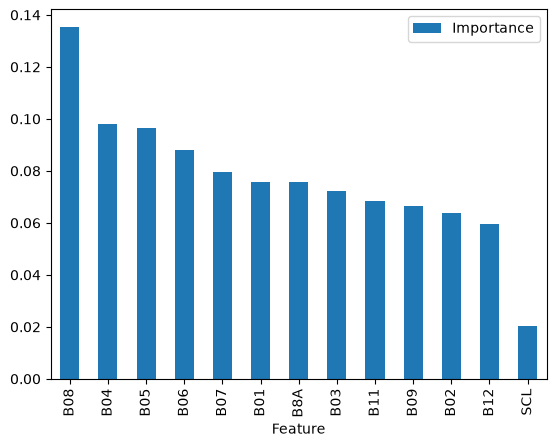

In [25]:
plotting.plot_model_feature_importance(training_dataframe=training_dataframe, model_file=model_file)

# Validate
* Predict
* Confusion matrix at UAV resolution
* Confusion matrix at Satellite resolution - take mode of UAV data

	Predict 15054 samples
Satellite training classes present: ['Seagrass', 'Seagrass submerged', 'Gracilaria', 'Gracilaria submerged', 'Ulva', 'Submerged vegetation', 'Microphytobenthos', 'Satmarsh', 'Unvegetated', 'Water', 'Terrestrial', 'Rock']. Predicted classes present: ['Seagrass', 'Seagrass submerged', 'Gracilaria', 'Gracilaria submerged', 'Ulva', 'Submerged vegetation', 'Microphytobenthos', 'Satmarsh', 'Unvegetated', 'Water', 'Terrestrial', 'Rock']. 


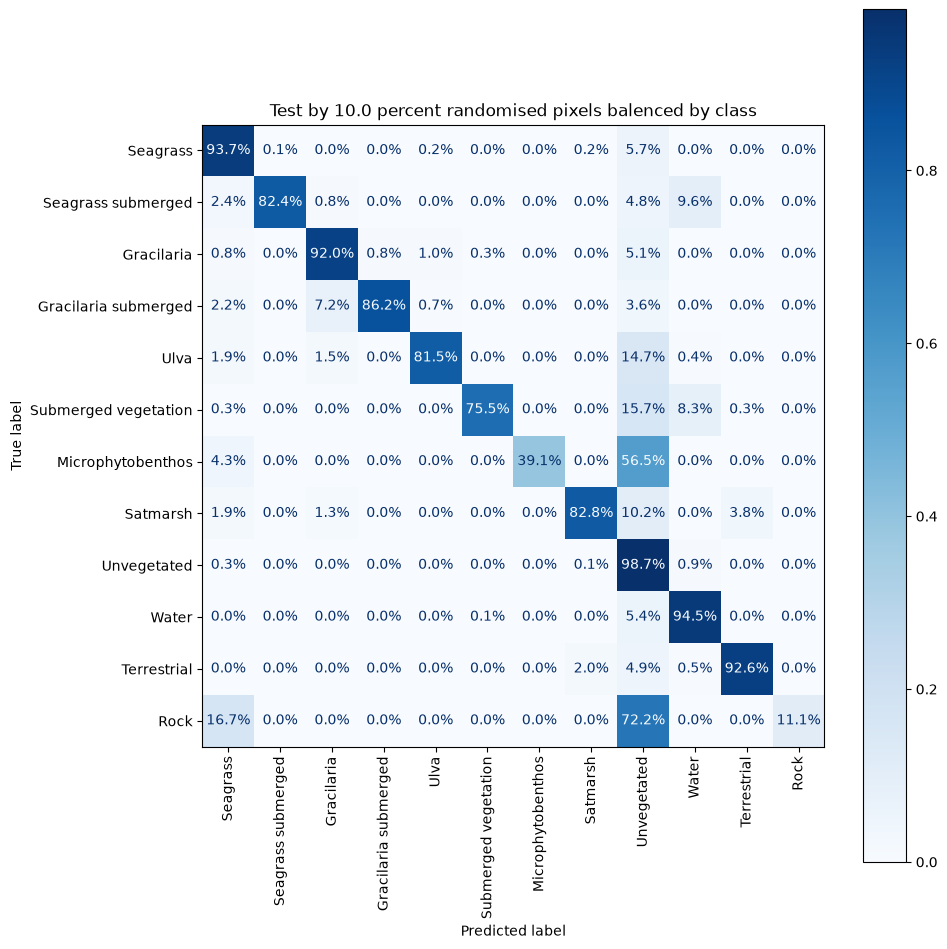

In [26]:
if not test_prediction_file.exists():
    model_feature_names_file = model_file.with_name("feature_names.csv")
    predictions = training.predict_samples(
        test_dataframe=test_dataframe,
        model_file=model_file,
        model_feature_names_file=model_feature_names_file)
    # save predictions with actual to csv
    predictions.to_csv(test_prediction_file, index=False)
else:
    print(f"Prediction file '{test_prediction_file.name}' already eixsts. Delete if you want to repredict.")
    predictions = pandas.read_csv(test_prediction_file)
    
print(
    f"Satellite training classes present: {[key for key, value in satellite_classes.items() if value in predictions['satellite_class_id'].unique()]}. "
    f"Predicted classes present: {[key for key, value in satellite_classes.items() if value in predictions['predicted_class_id'].unique()]}. "
     )

plot_filename = test_prediction_file.with_name("confusion_matrix.png")
plot_title = f"Test by {test_threshold*100} percent randomised pixels balenced by class"

training.confusion_matrix_of_pixels(
    truth=predictions["satellite_class_id"],
    predictions=predictions["predicted_class_id"],
    satellite_classes=satellite_classes,
    plot_filename=plot_filename,
    plot_title=plot_title
);
